# 05 · Seleção de algoritmos

Com as features definidas (nb 04), comparamos **famílias de algoritmos** sob as mesmas condições:
mesmas features, mesmos 3 folds temporais e hiperparâmetros razoáveis **sem tuning**. Queremos saber
qual família tem mais potencial, e não qual foi mais bem ajustada.

| Candidato | Por que testar |
|---|---|
| **Regressão logística** | baseline linear, interpretável e muito rápida; requer tratamento de nulos/escala |
| **Random Forest** | árvores em *bagging*: robusta, captura não linearidades |
| **XGBoost** | *gradient boosting*, estado da arte em dados tabulares |
| **LightGBM** | *gradient boosting* com histogramas: rápido para treinar e para inferir |
| **CatBoost** | *gradient boosting* com *ordered boosting*, menos propenso a overfitting |

**Critérios de escolha,** em ordem: (1) PR AUC médio e sua estabilidade entre folds; (2) ROC AUC /
Recall @ FPR 5%; (3) **custo operacional**: latência de inferência, tempo de treino e simplicidade de
implantação.

In [1]:
# Configuração comum a todos os notebooks do projeto
import sys, warnings
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent / "src"))
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from fraude import config as cfg, dados, metricas, graficos as gr

gr.aplicar_estilo()
pd.set_option("display.float_format", lambda x: f"{x:,.4f}")
pd.set_option("display.max_columns", 40)

import lightgbm as lgb
from xgboost import XGBClassifier
from catboost import CatBoostClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import FunctionTransformer, StandardScaler
from sklearn.impute import SimpleImputer
from fraude import validacao

In [2]:
%%time
base = dados.carregar_base()
dev = base[base["particao"] != "teste"].reset_index(drop=True)
folds = validacao.construir_folds(dev)   # mesmas features do nb 04 (configuração D)
print(len(folds), "folds |", folds[0].X_tr.shape[1], "features")

3 folds | 25 features
CPU times: total: 18.7 s
Wall time: 37.9 s


## 1. Candidatos

A regressão logística precisa de um pré-processamento próprio: transformação log com sinal (as
variáveis são muito assimétricas), imputação pela mediana **com indicador de ausência** (o nulo é
informativo, nb 01) e padronização. Os modelos de árvore recebem as features como estão e tratam
nulos nativamente (exceto Random Forest, que recebe imputação simples).

In [3]:
log_sinal = FunctionTransformer(lambda X: np.sign(X) * np.log1p(np.abs(X)))

candidatos = {
    "Regressão logística": make_pipeline(
        log_sinal, SimpleImputer(strategy="median", add_indicator=True), StandardScaler(),
        LogisticRegression(C=1.0, max_iter=3000)),
    "Random Forest": make_pipeline(
        SimpleImputer(strategy="median", add_indicator=True),
        RandomForestClassifier(n_estimators=500, min_samples_leaf=20, max_features="sqrt",
                               n_jobs=-1, random_state=cfg.SEED)),
    "XGBoost": XGBClassifier(n_estimators=400, learning_rate=0.03, max_depth=6, subsample=0.8,
                             colsample_bytree=0.8, min_child_weight=5, tree_method="hist",
                             n_jobs=-1, random_state=cfg.SEED),
    "LightGBM": lgb.LGBMClassifier(n_estimators=400, learning_rate=0.03, num_leaves=31, min_child_samples=100,
                                   subsample=0.8, subsample_freq=1, colsample_bytree=0.8,
                                   random_state=cfg.SEED, verbose=-1),
    "CatBoost": CatBoostClassifier(iterations=800, learning_rate=0.05, depth=6, random_seed=cfg.SEED,
                                   verbose=0, thread_count=-1, allow_writing_files=False),
}

In [4]:
%%time
resultados, oofs = [], {}
for nome, modelo in candidatos.items():
    r, oof = validacao.avaliar_cv(modelo, folds, nome=nome)
    resultados.append(r)
    oofs[nome] = oof
resultados = pd.concat(resultados, ignore_index=True)
comparacao = validacao.resumo_cv(resultados)
comparacao

CPU times: total: 4min 46s
Wall time: 47 s


,PR AUC (média),ROC AUC (média),Recall @ FPR 5% (média),treino (s) (média),predição (µs/transação) (média),PR AUC (dp),ROC AUC (dp)
modelo,,,,,,,
XGBoost,0.4182,0.8533,0.4844,1.0556,1.5235,0.0102,0.0007
LightGBM,0.4177,0.8534,0.4807,0.7963,6.6401,0.0093,0.0016
CatBoost,0.4163,0.8543,0.4802,5.7271,0.3164,0.0094,0.0018
Random Forest,0.3978,0.8454,0.4703,7.4181,7.9112,0.0060,0.0014
Regressão logística,0.3764,0.8486,0.4612,0.2363,1.0442,0.0028,0.0020


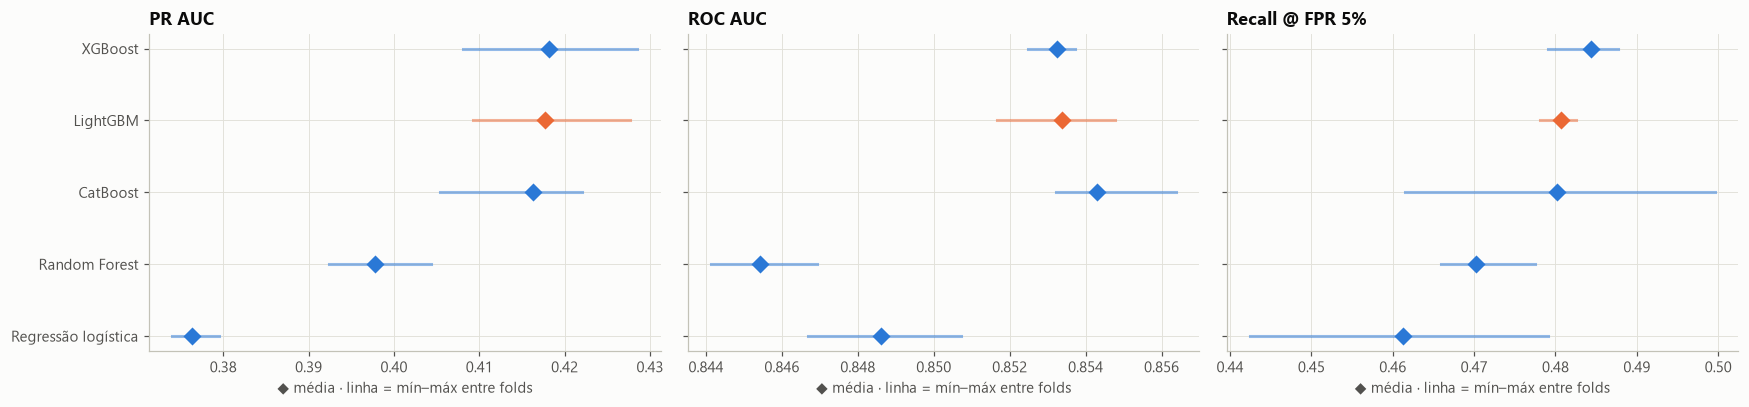

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(16, 3.8))
ordem = comparacao.index.tolist()
for ax, met in zip(axes, ["PR AUC", "ROC AUC", "Recall @ FPR 5%"]):
    for i, nome in enumerate(ordem):
        v = resultados.loc[resultados["modelo"] == nome, met]
        cor = gr.LARANJA if nome == "LightGBM" else gr.AZUL
        ax.plot([v.min(), v.max()], [i, i], color=cor, lw=2, alpha=0.5)
        ax.scatter(v.mean(), i, color=cor, s=70, marker="D", zorder=3)
    ax.set_yticks(range(len(ordem)), ordem if ax is axes[0] else [""] * len(ordem))
    ax.invert_yaxis()
    ax.set(title=met, xlabel="◆ média · linha = mín–máx entre folds")
plt.tight_layout()

**Leitura:**
- Os três *gradient boostings* (LightGBM, XGBoost, CatBoost) ficam **praticamente empatados**, com
  diferenças menores que a variação entre folds. Isso mostra que o limite está na informação das features,
  e não no algoritmo.
- **Random Forest** fica um degrau abaixo em PR AUC (~0,40) e é a pior em ROC AUC.
- A **regressão logística** tem ROC AUC razoável (~0,849), mas o **pior PR AUC (~0,38)**. Ela ordena
  bem a massa de transações, mas erra justamente no topo do ranking, onde estão as fraudes mais
  "óbvias" e onde se decide o bloqueio. As relações são fortemente não lineares (risco concentrado
  perto de zero em `f`, `l`, `m`; interações), o que um modelo linear não captura sem muita engenharia
  manual.

## 2. Tratamento do desbalanceamento: pesos ajudam?

Com 5% de fraude, é comum recorrer a *class weights* / *scale_pos_weight* ou a reamostragem. Testamos no
LightGBM. A hipótese é que pesos **não melhoram a ordenação** (que é o que AUC mede): eles apenas
deslocam as probabilidades, e o ponto de corte pode ser ajustado depois.

In [6]:
lgbm_base = candidatos["LightGBM"]
variantes = {
    "LightGBM (sem peso)": lgbm_base,
    "LightGBM (scale_pos_weight=5)": lgb.LGBMClassifier(**{**lgbm_base.get_params(), "scale_pos_weight": 5}),
    "LightGBM (balanceado ≈ 19)": lgb.LGBMClassifier(**{**lgbm_base.get_params(), "class_weight": "balanced"}),
}
res_peso, oof_peso = [], {}
for nome, m in variantes.items():
    r, o = validacao.avaliar_cv(m, folds, nome=nome)
    res_peso.append(r); oof_peso[nome] = o
res_peso = pd.concat(res_peso)
tab_peso = validacao.resumo_cv(res_peso)[["PR AUC (média)", "ROC AUC (média)", "Recall @ FPR 5% (média)"]]
tab_peso["prob. média prevista"] = [oof_peso[n]["p"].mean() for n in tab_peso.index]
tab_peso["taxa real de fraude"] = oof_peso["LightGBM (sem peso)"]["y"].mean()
tab_peso

,PR AUC (média),ROC AUC (média),Recall @ FPR 5% (média),prob. média prevista,taxa real de fraude
modelo,,,,,
LightGBM (sem peso),0.4177,0.8534,0.4807,0.0485,0.0565
LightGBM (scale_pos_weight=5),0.4160,0.8526,0.4835,0.1331,0.0565
LightGBM (balanceado ≈ 19),0.4111,0.8522,0.4749,0.2610,0.0565


Como esperado, os pesos **não melhoram a ordenação**: PR AUC e ROC AUC pioram levemente, e o
Recall @ FPR 5% varia dentro do ruído. Em compensação, **distorcem as probabilidades**: com peso
balanceado, a probabilidade média prevista (~26%) fica 4–5x acima da taxa real de fraude (~5,7%). **Decisão:** treinar sem pesos, preservando probabilidades interpretáveis, e tratar a
assimetria de custo **na escolha do ponto de corte** (notebook 08, perguntas 5 e 6).

## 3. Custo operacional (relevante para a resposta online, pergunta 7)

In [7]:
custo = comparacao[["treino (s) (média)", "predição (µs/transação) (média)"]].copy()
custo.columns = ["tempo de treino (s)", "predição em lote (µs/transação)"]
custo.sort_values("predição em lote (µs/transação)")

,tempo de treino (s),predição em lote (µs/transação)
modelo,,
CatBoost,5.7271,0.3164
Regressão logística,0.2363,1.0442
XGBoost,1.0556,1.5235
LightGBM,0.7963,6.6401
Random Forest,7.4181,7.9112


- **Treino:** o LightGBM é o boosting mais rápido (< 1 s por fold). CatBoost e Random Forest são
  ~7–9x mais lentos. Isso pesa num ciclo de retreino frequente e de tuning.
- **Predição em lote:** todos ficam em poucos **microssegundos por transação**. O CatBoost (árvores
  simétricas) é o mais rápido em lote. Em qualquer caso, a diferença é irrelevante perto do restante da
  cadeia online (rede, busca de features).
- A latência que importa online é a **por requisição única** (sem o benefício do lote), medida no
  notebook 09.

## 4. Decisão

| Critério | LightGBM | XGBoost | CatBoost | Random Forest | Logística |
|---|---|---|---|---|---|
| PR AUC / ROC AUC | ✅ topo (empate técnico) | ✅ topo | ✅ topo | ⚠️ abaixo | ❌ bem abaixo |
| Estabilidade entre folds | ✅ | ✅ | ✅ | ✅ | ✅ |
| Treino / inferência | ✅ treino mais rápido; µs | ✅ µs | ⚠️ treino ~7x mais lento | ❌ pesado | ✅ mínimo |
| Nulos nativos | ✅ | ✅ | ✅ | ❌ | ❌ |
| Explicabilidade (SHAP) | ✅ TreeSHAP | ✅ | ✅ | ✅ | ✅ coeficientes |

**Escolha: LightGBM.** Está no grupo de melhor desempenho, em empate técnico com XGBoost e CatBoost
(diferenças de PR AUC < 0,002, muito menores que a variação entre folds). O desempate é **operacional**:
treino mais rápido (tuning e retreinos frequentes), artefato pequeno, nulos nativos e suporte maduro a
SHAP e a exportação (ONNX/Treelite). O XGBoost seria uma escolha igualmente defensável. A regressão logística fica registrada como **plano B** para um
cenário de latência extrema ou exigência regulatória de modelo linear. A perda de desempenho dela foi
quantificada aqui.

➡️ **Próximo passo (06):** tuning, calibração, explicabilidade e treino do modelo final.